# GoEmotions - EDA and data preparation

First look at the data with basic tools only (pandas, matplotlib, counting), then the data preparation used by every model.
Dataset: GoEmotions, *simplified* version (Reddit comments, 27 emotions + neutral, several labels possible per comment).

Run from `notebooks/`. Figures are saved to `results/eda_simple/`, the prepared splits to `data/processed/` (not committed: run this notebook once before the modelling notebooks).

In [1]:
%matplotlib inline
import os
import re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

FIG_DIR = os.path.join("..", "results", "eda_simple")
os.makedirs(FIG_DIR, exist_ok = True)

c:\Users\fzzn7\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%pip install datasets 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load the data

In [3]:
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
label_names = ds["train"].features["labels"].feature.names

df_train = ds["train"].to_pandas()
df_val = ds["validation"].to_pandas()
df_test = ds["test"].to_pandas()

print("Number of labels:", len(label_names))
print("Train:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)
df_train.head()

Number of labels: 28
Train: (43410, 3)
Validation: (5426, 3)
Test: (5427, 3)


,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj


In [4]:
print(label_names)

['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


## 2. Basic checks

In [5]:
for name, df in [("Train", df_train), ("Validation", df_val), ("Test", df_test)]:
    print(name)
    print("  Missing values:", df.isna().sum().sum())
    print("  Empty texts:", (df["text"].str.strip() == "").sum())
    print("  Comments with no label:", (df["labels"].apply(len) == 0).sum())

Train
  Missing values: 0
  Empty texts: 0
  Comments with no label: 0
Validation
  Missing values: 0
  Empty texts: 0
  Comments with no label: 0
Test
  Missing values: 0
  Empty texts: 0
  Comments with no label: 0


In [6]:
# replace the label ids by their names to make the data readable
df_train["label_names"] = df_train["labels"].apply(lambda l: [label_names[i] for i in l])
df_train[["text", "label_names"]].head(10)

,text,label_names
0,My favourite food is anything I didn't have to...,[neutral]
1,"Now if he does off himself, everyone will thin...",[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[anger]
3,To make her feel threatened,[fear]
4,Dirty Southern Wankers,[annoyance]
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,[surprise]
6,Yes I heard abt the f bombs! That has to be wh...,[gratitude]
7,We need more boards and to create a bit more s...,"[desire, optimism]"
8,Damn youtube and outrage drama is super lucrat...,[admiration]
9,It might be linked to the trust factor of your...,[neutral]


## 3. How often does each emotion appear?

In [7]:
all_labels_train = [lab for l in df_train["label_names"] for lab in l]
label_counts = pd.Series(Counter(all_labels_train)).sort_values(ascending = False)

label_table = pd.DataFrame({"count": label_counts,
                            "percent_of_comments": (100 * label_counts / len(df_train)).round(2)})
label_table

,count,percent_of_comments
neutral,14219,32.76
admiration,4130,9.51
approval,2939,6.77
gratitude,2662,6.13
annoyance,2470,5.69
amusement,2328,5.36
curiosity,2191,5.05
love,2086,4.81
disapproval,2022,4.66
optimism,1581,3.64


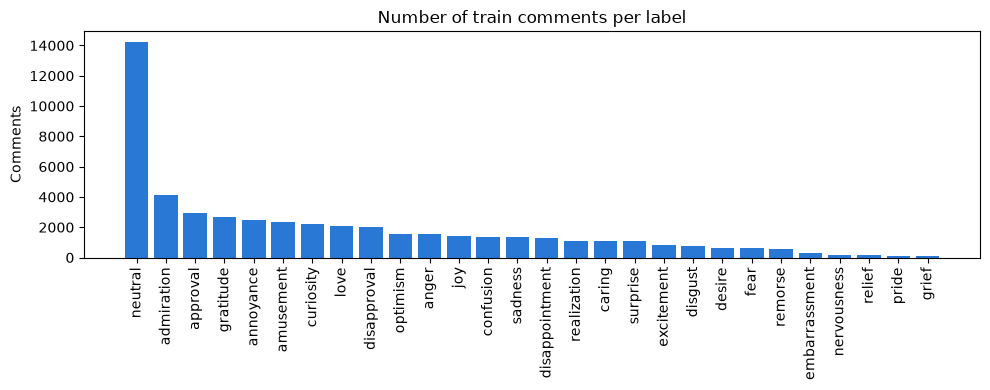

In [8]:
fig, ax = plt.subplots(figsize = (10, 4))
ax.bar(label_counts.index, label_counts.values, color = "#2a78d6")
ax.set_title("Number of train comments per label")
ax.set_ylabel("Comments")
plt.xticks(rotation = 90)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "label_counts.png"))
plt.show()

In [9]:
print("Most frequent label:", label_counts.index[0], label_counts.iloc[0])
print("Least frequent label:", label_counts.index[-1], label_counts.iloc[-1])
print("Ratio most / least frequent:", round(label_counts.iloc[0] / label_counts.iloc[-1], 1))
label_counts_no_neutral = label_counts.drop("neutral")
print("Ratio most / least frequent (without neutral):", round(label_counts_no_neutral.iloc[0] / label_counts_no_neutral.iloc[-1], 1))

Most frequent label: neutral 14219
Least frequent label: grief 77
Ratio most / least frequent: 184.7
Ratio most / least frequent (without neutral): 53.6


## 4. How many labels per comment?

In [10]:
df_train["nb_labels"] = df_train["labels"].apply(len)
nb_labels_counts = df_train["nb_labels"].value_counts().sort_index()
print(nb_labels_counts)
print("Percent of comments with one label:", round(100 * (df_train["nb_labels"] == 1).mean(), 1))

nb_labels
1    36308
2     6541
3      532
4       28
5        1
Name: count, dtype: int64
Percent of comments with one label: 83.6


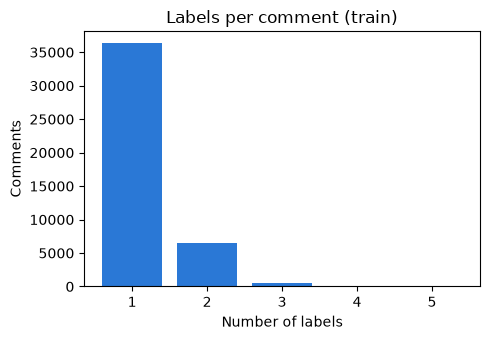

In [11]:
fig, ax = plt.subplots(figsize = (5, 3.5))
ax.bar(nb_labels_counts.index.astype(str), nb_labels_counts.values, color = "#2a78d6")
ax.set_title("Labels per comment (train)")
ax.set_xlabel("Number of labels")
ax.set_ylabel("Comments")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "labels_per_comment.png"))
plt.show()

## 5. Which labels appear together?

In [12]:
pairs = Counter()
for l in df_train["label_names"]:
    if len(l) >= 2:
        for i in range(len(l)):
            for j in range(i + 1, len(l)):
                pairs[tuple(sorted([l[i], l[j]]))] += 1

top_pairs = pd.DataFrame(pairs.most_common(10), columns = ["pair", "count"])
top_pairs

,pair,count
0,"(admiration, gratitude)",279
1,"(anger, annoyance)",269
2,"(admiration, approval)",246
3,"(confusion, curiosity)",212
4,"(approval, neutral)",202
5,"(admiration, love)",192
6,"(annoyance, disapproval)",178
7,"(disappointment, sadness)",133
8,"(annoyance, neutral)",132
9,"(admiration, joy)",126


## 6. Length of the comments

Words are counted by splitting on spaces (`str.split()`), not with an NLP tokenizer, so these are approximate word counts, not model tokens.

In [13]:
df_train["nb_words"] = df_train["text"].str.split().apply(len)
df_train["nb_words"].describe()

count    43410.000000
mean        12.840175
std          6.701597
min          1.000000
25%          7.000000
50%         12.000000
75%         18.000000
max         33.000000
Name: nb_words, dtype: float64

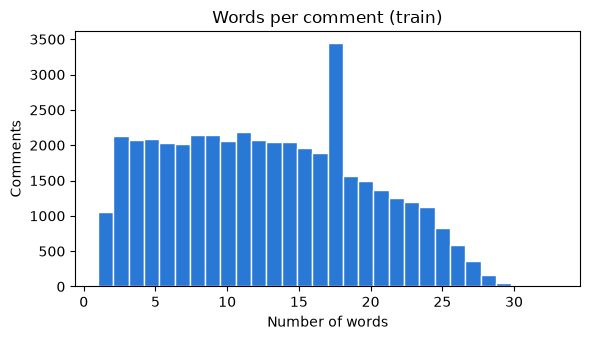

In [14]:
fig, ax = plt.subplots(figsize = (6, 3.5))
ax.hist(df_train["nb_words"], bins = 30, color = "#2a78d6", edgecolor = "white")
ax.set_title("Words per comment (train)")
ax.set_xlabel("Number of words")
ax.set_ylabel("Comments")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "comment_length.png"))
plt.show()

In [15]:
# average length for each label
df_exploded = df_train.explode("label_names")
length_by_label = df_exploded.groupby("label_names")["nb_words"].mean().round(1).sort_values()
print("Shortest on average:")
print(length_by_label.head(3))
print("Longest on average:")
print(length_by_label.tail(3))

Shortest on average:
label_names
excitement    11.3
gratitude     11.8
admiration    11.9
Name: nb_words, dtype: float64
Longest on average:
label_names
desire         14.6
realization    15.2
optimism       15.5
Name: nb_words, dtype: float64


## 7. Some examples

In [16]:
for emotion in ["gratitude", "anger", "sadness", "curiosity", "neutral"]:
    examples = df_exploded[df_exploded["label_names"] == emotion]["text"].sample(3, random_state = 0)
    print("---", emotion)
    for t in examples:
        print("  ", t)

--- gratitude
   Thanks for reminding me not to have kids
   This is exactly what I was looking for! Thank you so much!
   thank you!
--- anger
   I've always hated the 610/45 interchange. Everyone slows to a crawl when there is no need to slow down.
   obviously, its just a stupid question
   FUCK LES BRUNS
--- sadness
   I needed to read this because I felt so bad for this guy... I just can't imagine a long walk home in winter.
   Pls not granny :(
   Levels mate. Absolutely obsessed with our dominance.
--- curiosity
   #WHERE ARE THE TURTLES
   Really??
   are u ugly?
--- neutral
   Elections have consequences.
   I thought that already happened when [NAME] was confirmed. I was told that would be the end of America!
   Castle Danger is killing it with tasty beverage. I'm jealous!


## 8. Most frequent words

In [17]:
def tokenize(text):
    words = re.findall(r"[a-z']+", text.lower())
    return [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]

all_words = Counter()
for t in df_train["text"]:
    all_words.update(tokenize(t))
print("Most frequent words overall:")
print(all_words.most_common(15))

Most frequent words overall:
[('just', 3433), ('like', 3276), ("it's", 1973), ('love', 1915), ("i'm", 1892), ('people', 1784), ('good', 1731), ('really', 1461), ("don't", 1449), ('think', 1440), ('know', 1423), ('thanks', 1280), ('lol', 1217), ('time', 1208), ("that's", 1142)]


In [18]:
for emotion in ["gratitude", "anger", "sadness", "amusement", "fear"]:
    words_emotion = Counter()
    for t in df_exploded[df_exploded["label_names"] == emotion]["text"]:
        words_emotion.update(tokenize(t))
    print(emotion, ":", [w for w, n in words_emotion.most_common(10)])

gratitude : ['thanks', 'thank', 'good', 'just', "i'm", 'know', 'really', 'glad', 'like', "i'll"]
anger : ['fuck', 'hate', 'fucking', 'just', 'people', 'like', "don't", "it's", 'stupid', 'shit']
sadness : ['sad', 'sorry', "i'm", 'just', 'bad', 'feel', 'like', "it's", 'really', 'sadly']
amusement : ['lol', 'haha', 'funny', 'just', 'like', 'fun', "it's", 'lmao', 'good', 'people']
fear : ["i'm", 'scared', 'terrible', 'afraid', 'scary', 'horrible', 'like', 'just', "it's", 'terrifying']


In [19]:
# punctuation: share of comments with "?" or "!" for a few labels
df_exploded["has_question"] = df_exploded["text"].str.contains("\\?")
df_exploded["has_exclamation"] = df_exploded["text"].str.contains("!")
punct = df_exploded.groupby("label_names")[["has_question", "has_exclamation"]].mean().round(2)
punct.loc[["curiosity", "confusion", "excitement", "gratitude", "neutral", "sadness"]]

,has_question,has_exclamation
label_names,,
curiosity,0.81,0.08
confusion,0.51,0.06
excitement,0.04,0.42
gratitude,0.04,0.38
neutral,0.09,0.10
sadness,0.05,0.07


## 9. Duplicates between splits

Texts are compared **after lowercasing**, so "Thank you." and "thank you." count as the same text.

In [20]:
train_texts = set(df_train["text"].str.lower())
val_texts = set(df_val["text"].str.lower())

print("Duplicate texts inside train:", df_train["text"].str.lower().duplicated().sum())
print("Validation texts also in train:", df_val["text"].str.lower().isin(train_texts).sum())
print("Test texts also in train:", df_test["text"].str.lower().isin(train_texts).sum())
print("Test texts also in validation:", df_test["text"].str.lower().isin(val_texts).sum())

Duplicate texts inside train: 220
Validation texts also in train: 49
Test texts also in train: 42
Test texts also in validation: 14


In [21]:
df_test[df_test["text"].str.lower().isin(train_texts)]["text"].head(10)

6                  You’re welcome
329                   thank you !
355                       [NAME].
460         How do you know this?
558                    Thank you.
691               This is amazing
707                    Very cool.
999                 What a legend
1080    It really do be like that
1087                I miss [NAME]
Name: text, dtype: str

## 10. Do the three splits have the same label distribution?

In [22]:
def label_percent(df):
    names = [label_names[i] for l in df["labels"] for i in l]
    return 100 * pd.Series(Counter(names)) / len(df)

split_compare = pd.DataFrame({"train": label_percent(df_train),
                              "validation": label_percent(df_val),
                              "test": label_percent(df_test)}).round(2)
split_compare = split_compare.sort_values("train", ascending = False)
split_compare.head(10)

,train,validation,test
neutral,32.76,32.55,32.93
admiration,9.51,8.99,9.29
approval,6.77,7.32,6.47
gratitude,6.13,6.60,6.49
annoyance,5.69,5.58,5.90
amusement,5.36,5.58,4.86
curiosity,5.05,4.57,5.23
love,4.81,4.64,4.39
disapproval,4.66,5.38,4.92
optimism,3.64,3.85,3.43


In [23]:
print("Largest difference between splits (percentage points):", round((split_compare.max(axis = 1) - split_compare.min(axis = 1)).max(), 2))

Largest difference between splits (percentage points): 0.85


# Data preparation

The official splits are kept, with three cleaning choices (to be confirmed by the team, see `ai_governance/CONTRIBUTIONS.md`):

1. **Duplicates inside train:** comments with the same text (after lowercasing) are merged into one row, whose labels are the union of the labels of the copies. This keeps one example per text and does not throw away the labels of the 61 groups that disagree.
2. **Validation and test texts already seen in train** are removed, so a model is never scored on a text it was trained on.
3. **Test texts also in validation** are removed from test, because validation is used to tune the thresholds.

Light preprocessing only: the text is kept as it is (case, punctuation, `[NAME]` placeholders), because punctuation and capitals carry emotion (section 8). Each model does its own tokenization.

## 11. Clean the splits

In [37]:
def normalize(text):
    return text.lower()

df_train_clean = df_train[["id", "text", "labels"]].copy()
df_train_clean["text_norm"] = df_train_clean["text"].apply(normalize)

# merge duplicate texts in train: keep the first id and text, take the union of the labels
df_train_clean = (df_train_clean
                  .groupby("text_norm", sort = False)
                  .agg(id = ("id", "first"), text = ("text", "first"),
                       labels = ("labels", lambda ls: sorted(set(i for l in ls for i in l))))
                  .reset_index())

print("Train rows before:", len(df_train), "after:", len(df_train_clean), "removed:", len(df_train) - len(df_train_clean))

Train rows before: 43410 after: 43190 removed: 220


In [38]:
train_norm = set(df_train_clean["text_norm"])

df_val_clean = df_val[["id", "text", "labels"]].copy()
df_val_clean["text_norm"] = df_val_clean["text"].apply(normalize)
df_val_clean = df_val_clean[~df_val_clean["text_norm"].isin(train_norm)].reset_index(drop = True)

val_norm = set(df_val_clean["text_norm"])

df_test_clean = df_test[["id", "text", "labels"]].copy()
df_test_clean["text_norm"] = df_test_clean["text"].apply(normalize)
df_test_clean = df_test_clean[~df_test_clean["text_norm"].isin(train_norm)]
df_test_clean = df_test_clean[~df_test_clean["text_norm"].isin(val_norm)].reset_index(drop = True)

print("Validation rows before:", len(df_val), "after:", len(df_val_clean), "removed:", len(df_val) - len(df_val_clean))
print("Test rows before:", len(df_test), "after:", len(df_test_clean), "removed:", len(df_test) - len(df_test_clean))

Validation rows before: 5426 after: 5377 removed: 49
Test rows before: 5427 after: 5379 removed: 48


In [39]:
# checks: no text shared between splits anymore
print("Validation texts in train:", df_val_clean["text_norm"].isin(train_norm).sum())
print("Test texts in train:", df_test_clean["text_norm"].isin(train_norm).sum())
print("Test texts in validation:", df_test_clean["text_norm"].isin(val_norm).sum())
print("Duplicate texts inside train:", df_train_clean["text_norm"].duplicated().sum())

Validation texts in train: 0
Test texts in train: 0
Test texts in validation: 0
Duplicate texts inside train: 0


### 11.1. Automated data leakage checks

We use assertions to ensure that no normalized text
is shared between the training, validation and test sets.
These checks prevent the pipeline from continuing if
data leakage is detected.

In [40]:
assert not df_val_clean["text_norm"].isin(train_norm).any()
assert not df_test_clean["text_norm"].isin(train_norm).any()
assert not df_test_clean["text_norm"].isin(val_norm).any()

assert not df_train_clean["text_norm"].duplicated().any()

print("All leakage checks passed.")

All leakage checks passed.


In [41]:
for name, df in [
    ("Validation", df_val_clean),
    ("Test", df_test_clean)
]:
    print(name, "- Internal duplicates:",
          df["text_norm"].duplicated().sum())

Validation - Internal duplicates: 2
Test - Internal duplicates: 0


Two repeated text occurrences remain within the validation set. No duplicates remain within the test set.

These do not create overlap between splits, but may slightly affect validation metrics. We propose keeping them to maintain consistency across our experiments.

### 11.2. Duplicate label consistency

Identical comments may have different emotion annotations.
We analyze these disagreements to assess the impact
of merging their labels.

In [42]:
duplicate_analysis = df_train[["text", "labels"]].copy()
duplicate_analysis["text_norm"] = duplicate_analysis["text"].str.lower()

label_variations = duplicate_analysis.groupby("text_norm")["labels"].apply(
    lambda labels: len(set(tuple(sorted(l)) for l in labels))
)

conflicting_groups = label_variations[label_variations > 1]

print("Duplicate groups with different labels:", len(conflicting_groups))

Duplicate groups with different labels: 61


In [43]:
neutral_id = label_names.index("neutral")

def has_neutral_conflict(labels):
    return neutral_id in labels and len(labels) > 1

before = df_train["labels"].apply(has_neutral_conflict).sum()

after = df_train_clean["labels"].apply(
    has_neutral_conflict
).sum()

print("Neutral + other emotions before cleaning:", before)
print("Neutral + other emotions after cleaning:", after)

Neutral + other emotions before cleaning: 1396
Neutral + other emotions after cleaning: 1412


**Interpretation**

We identified 61 groups of identical texts with different
emotion annotations.

Before cleaning, 1,396 training comments contained both
Neutral and at least one other emotion. After merging
duplicates, this number increased to 1,412.

Since these associations already exist in the original
dataset, we preserve the labels rather than arbitrarily
removing Neutral. However, merging labels may introduce
additional ambiguity, which remains a limitation of our
preprocessing strategy.

## 12. Labels at three levels

The 28 labels are mapped to the 6 Ekman emotions and to 3 sentiment groups with the official mappings from the GoEmotions documentation (`ekman_mapping.json`, `sentiment_mapping.json` in google-research/goemotions). Neutral stays its own class. A comment gets a group when at least one of its emotions belongs to it, so every level stays multi-label.

In [44]:
ekman_mapping = {
    "anger": ["anger", "annoyance", "disapproval"],
    "disgust": ["disgust"],
    "fear": ["fear", "nervousness"],
    "joy": ["joy", "amusement", "approval", "excitement", "gratitude", "love", "optimism", "relief", "pride", "admiration", "desire", "caring"],
    "sadness": ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
}
sentiment_mapping = {
    "positive": ["amusement", "excitement", "joy", "love", "desire", "optimism", "caring", "pride", "admiration", "gratitude", "relief", "approval"],
    "negative": ["fear", "nervousness", "remorse", "embarrassment", "disappointment", "sadness", "grief", "disgust", "anger", "annoyance", "disapproval"],
    "ambiguous": ["realization", "surprise", "curiosity", "confusion"],
}

# every emotion must appear in exactly one group of each mapping
emotions = [l for l in label_names if l != "neutral"]
for name, mapping in [("Ekman", ekman_mapping), ("Sentiment", sentiment_mapping)]:
    mapped = [e for group in mapping.values() for e in group]
    print(name, "- all emotions mapped once:", sorted(mapped) == sorted(emotions))

Ekman - all emotions mapped once: True
Sentiment - all emotions mapped once: True


In [45]:
def to_group(names, mapping):
    groups = set()
    for n in names:
        if n == "neutral":
            groups.add("neutral")
        for g, members in mapping.items():
            if n in members:
                groups.add(g)
    return sorted(groups)

for df in [df_train_clean, df_val_clean, df_test_clean]:
    df["labels_28"] = df["labels"].apply(lambda l: [label_names[i] for i in l])
    df["labels_ekman"] = df["labels_28"].apply(lambda l: to_group(l, ekman_mapping))
    df["labels_sentiment"] = df["labels_28"].apply(lambda l: to_group(l, sentiment_mapping))

df_train_clean[["text", "labels_28", "labels_ekman", "labels_sentiment"]].head(8)

,text,labels_28,labels_ekman,labels_sentiment
0,My favourite food is anything I didn't have to...,[neutral],[neutral],[neutral]
1,"Now if he does off himself, everyone will thin...",[neutral],[neutral],[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[anger],[anger],[negative]
3,To make her feel threatened,[fear],[fear],[negative]
4,Dirty Southern Wankers,[annoyance],[anger],[negative]
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,[surprise],[surprise],[ambiguous]
6,Yes I heard abt the f bombs! That has to be wh...,[gratitude],[joy],[positive]
7,We need more boards and to create a bit more s...,"[desire, optimism]",[joy],[positive]


In [46]:
def group_counts(df, column):
    return pd.Series(Counter(g for l in df[column] for g in l)).sort_values(ascending = False)

print("Ekman (train comments per group):")
print(group_counts(df_train_clean, "labels_ekman"))
print("Sentiment (train comments per group):")
print(group_counts(df_train_clean, "labels_sentiment"))

Ekman (train comments per group):
joy         17278
neutral     14183
anger        5568
surprise     5358
sadness      3255
disgust       792
fear          725
dtype: int64
Sentiment (train comments per group):
positive     17278
neutral      14183
negative      9814
ambiguous     5358
dtype: int64


## 13. Save the prepared splits

In [47]:
OUT_DIR = os.path.join("..", "data", "processed")
os.makedirs(OUT_DIR, exist_ok = True)

columns = ["id", "text", "labels_28", "labels_ekman", "labels_sentiment"]
df_train_clean[columns].to_parquet(os.path.join(OUT_DIR, "train.parquet"), index = False)
df_val_clean[columns].to_parquet(os.path.join(OUT_DIR, "validation.parquet"), index = False)
df_test_clean[columns].to_parquet(os.path.join(OUT_DIR, "test.parquet"), index = False)

print("Saved to", OUT_DIR)
print("Train:", len(df_train_clean), "Validation:", len(df_val_clean), "Test:", len(df_test_clean))

Saved to ..\data\processed
Train: 43190 Validation: 5377 Test: 5379


In [48]:
for split in ["train", "validation", "test"]:
    path = os.path.join(OUT_DIR, f"{split}.parquet")
    df = pd.read_parquet(path)

    assert list(df.columns) == columns
    assert not df.isna().any().any()
    assert df["labels_28"].apply(len).gt(0).all()

    print(f"{split}: {df.shape} - OK")

train: (43190, 5) - OK
validation: (5377, 5) - OK
test: (5379, 5) - OK


To load them in another notebook:

```python
df_train = pd.read_parquet(os.path.join("..", "data", "processed", "train.parquet"))
```

## 14. Summary

**EDA**
- **Size:** 43,410 train / 5,426 validation / 5,427 test comments, 28 labels (27 emotions + neutral). No missing values, no empty texts and no comment without a label, in all three splits.
- **Strong imbalance:** `neutral` is on 32.8% of train comments. The most frequent emotion (admiration, 4,130) appears 54 times more often than the rarest (grief, 77). Pride, relief, nervousness and grief each have fewer than 200 train examples.
- **Mostly single-label:** 83.6% of comments have one label, 15.1% have two. The labels that go together are close emotions: anger + annoyance, confusion + curiosity, disappointment + sadness, admiration + gratitude.
- **Short texts:** 12 words on median, 33 at most (counted by splitting on spaces, not tokenizer tokens). Length barely changes between emotions, so it is not a useful feature on its own.
- **Words and punctuation carry a lot of signal:** "thanks" for gratitude, "lol/haha" for amusement, "scared/afraid" for fear; 81% of curiosity comments contain a `?` and 42% of excitement comments a `!`. Punctuation is preserved during data preparation. Its use during TF-IDF vectorization will be investigated.
- **Labels are noisy:** some examples look wrong or ambiguous, so part of the model errors will be annotation errors.
- **Duplicates (compared after lowercasing):** 220 repeated texts inside train, 49 validation and 42 test texts also in train, and 14 test texts also in validation. They are short generic comments such as "Thank you.".
- **Splits are consistent:** label shares differ by less than 1 percentage point between train, validation and test.

**Data preparation**
- Train duplicates merged with the union of their labels: 43,410 → 43,190 rows.
- Validation and test texts already seen in train removed, and test texts seen in validation removed: validation 5,426 → 5,377, test 5,427 → 5,379. No text is shared between splits anymore.
- Labels built at three levels (28 labels, Ekman 6 + neutral, sentiment 3 + neutral) with the official GoEmotions mappings, saved to `data/processed/`.
- Automated assertions confirm that no normalized text is shared between the three splits.
- 61 groups of duplicate training texts have different annotations. Label unions are preserved, with their limitations documented.
- All three exported Parquet files were successfully reloaded and passed schema, missing-value and label checks.

**Consequence for modelling:** due to the strong class imbalance, macro-F1 will be our primary metric, complemented by micro-F1 and per-class metrics. Accuracy is insufficient as a primary metric because it hides poor performance on the rare classes. Class weighting and per-class decision thresholds will be investigated during model development.